<a href="https://colab.research.google.com/github/blackburn3333/Forensic-Anatomy-of-an-AI-Edited-Photo/blob/main/Forensic_Anatomy_of_an_AI_Edited_Photo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q c2pa-python pillow opencv-python-headless matplotlib numpy pandas
!apt-get -qq install -y libimage-exiftool-perl

In [ ]:
import cv2
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
import os, json, struct, subprocess
from PIL import Image
from c2pa import Reader


In [ ]:
ORIGINAL_PATH = "original.jpg"
EDITED_IMAGES = {
    "Google Gemini Plus": "Gemini_Generated_Image_nmq5vwnmq5vwnmq5.jpg",
    "OpenAI ChatGPT Pro": "ChatGPT-Golden-Hour Kayaking Reflections.png",
    "Anthropic Claude Free": "claude-kayak_golden_hour.jpg",
    "Manus Free": "manus-golden_hour_kayak.png",
}

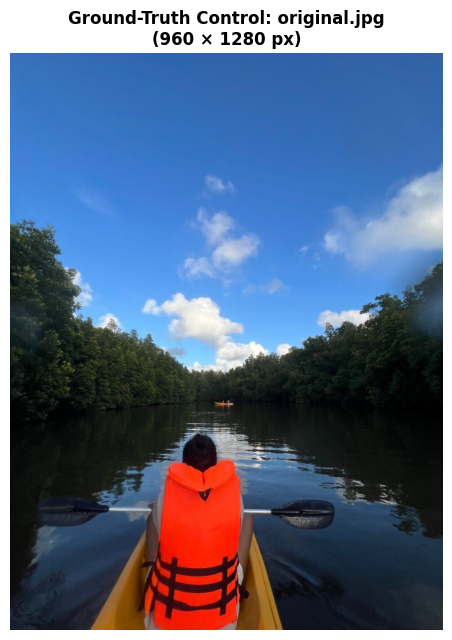

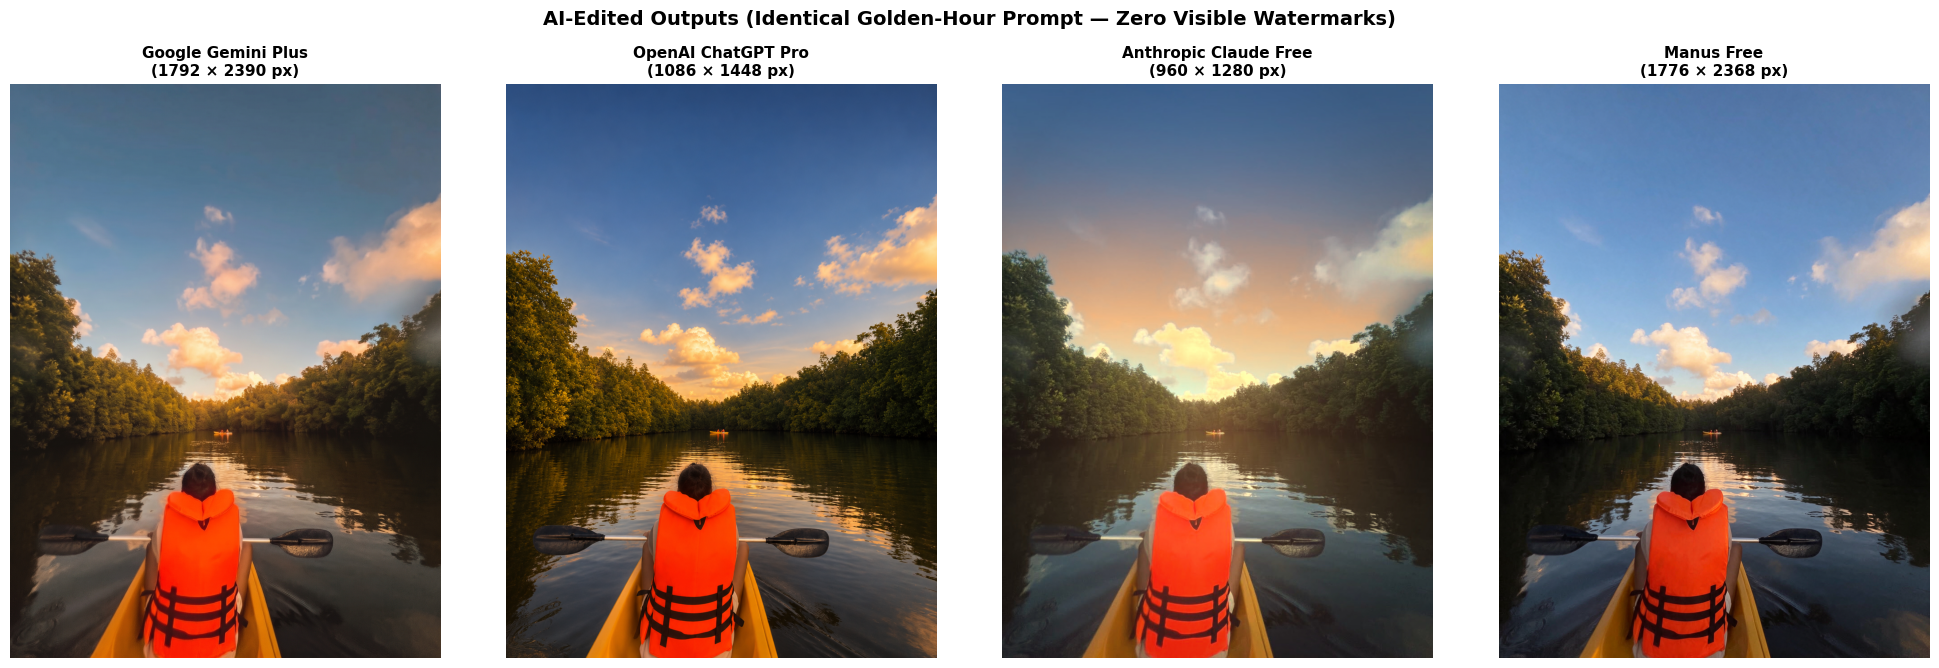

In [ ]:
def load_rgb(path):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Could not find file: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 2. Load and display the Ground-Truth Original Image
orig_img = load_rgb(ORIGINAL_PATH)
h_orig, w_orig = orig_img.shape[:2]

plt.figure(figsize=(5, 6.5))
plt.imshow(orig_img)
plt.title(f"Ground-Truth Control: original.jpg\n({w_orig} × {h_orig} px)", fontsize=12, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

# 3. Load and display all four AI-edited images in ONE horizontal row (1x4)
fig, axes = plt.subplots(1, 4, figsize=(20, 6.5))

for ax, (platform, path) in zip(axes, EDITED_IMAGES.items()):
    img = load_rgb(path)
    h, w = img.shape[:2]
    ax.imshow(img)
    ax.set_title(f"{platform}\n({w} × {h} px)", fontsize=11, fontweight="bold")
    ax.axis("off")

plt.suptitle("AI-Edited Outputs (Identical Golden-Hour Prompt — Zero Visible Watermarks)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("section1_all_outputs_row.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
def inspect_binary_sections(filepath):
    with open(filepath, "rb") as f:
        data = f.read()

    file_size = len(data)
    ext = os.path.splitext(filepath)[1].lower()
    sections = []
    trailing_bytes = 0

    if ext == ".png" and data[:8] == b"\x89PNG\r\n\x1a\n":
        pos = 8
        while pos < file_size:
            length, chunk_type = struct.unpack(">I4s", data[pos:pos+8])
            ctype = chunk_type.decode("latin1")
            sections.append(f"{ctype} ({length}B)")
            pos += 12 + length
            if ctype == "IEND":
                trailing_bytes = file_size - pos
                break
    elif ext in [".jpg", ".jpeg"] and data[:2] == b"\xff\xd8":
        pos = 2
        while pos < file_size - 1:
            if data[pos] != 0xFF:
                break
            marker = data[pos+1]
            if marker == 0xD9:  # EOI (End of Image)
                trailing_bytes = file_size - (pos + 2)
                break
            if marker == 0xDA:  # SOS (Start of Scan - compressed entropy data follows)
                eoi_idx = data.rfind(b"\xff\xd9")
                if eoi_idx != -1:
                    trailing_bytes = file_size - (eoi_idx + 2)
                sections.append("SOS (Image Stream)")
                break
            seg_len = struct.unpack(">H", data[pos+2:pos+4])[0]
            sig = data[pos+4:pos+14]
            sections.append(f"0xFF{marker:02X} ({seg_len}B, sig={sig[:6]})")
            pos += 2 + seg_len

    return file_size, sections, trailing_bytes

for label, fname in FILES.items():
    print(f"\n{'='*75}")
    print(f"[{label}] -> {fname}")
    print(f"{'='*75}")

    # 1. Binary Container Structure & Trailing Bytes
    fsize, chunks, trailing = inspect_binary_sections(fname)
    print(f"  File Size        : {fsize:,} bytes | Trailing Data After EOF: {trailing} bytes")
    print(f"  Binary Segments  : {', '.join(chunks[:12])}" + (" ..." if len(chunks) > 12 else ""))

    # 2. Pillow Info Dictionary (Hidden PNG text chunks / ICC profiles / XMP)
    with Image.open(fname) as im:
        hidden_keys = {k: (v[:80] + "..." if isinstance(v, (str, bytes)) and len(v) > 80 else v)
                       for k, v in im.info.items()}
        print(f"  PIL Hidden Keys  : {list(hidden_keys.keys()) if hidden_keys else 'None'}")
        for k, v in hidden_keys.items():
            if k != "icc_profile":
                print(f"    - {k}: {v}")

    # 3. Full ExifTool Dump (Filtered for non-standard/hidden tags)
    exif_out = subprocess.check_output(["exiftool", "-s", "-G", fname]).decode("utf-8", errors="ignore")
    meta_lines = [l for l in exif_out.splitlines() if not l.startswith("[File]") and not l.startswith("[ExifTool]")]
    print(f"  ExifTool Tags ({len(meta_lines)} found):")
    for line in meta_lines[:15]:
        print(f"    {line}")

    # 4. C2PA / JUMBF Content Credentials Check
    try:
        with Reader(fname) as reader:
            manifest = json.loads(reader.json())
            active_id = manifest.get("active_manifest")
            active = manifest["manifests"][active_id]
            print(f"  [C2PA STORE FOUND] Generator: {active.get('claim_generator')}")
            print(f"    Assertions: {[a.get('label') for a in active.get('assertions', [])]}")
    except Exception:
        print("  [C2PA STORE]     : None")


[Original (Control)] -> original.jpg
  File Size        : 86,948 bytes | Trailing Data After EOF: 0 bytes
  Binary Segments  : 0xFFE0 (16B, sig=b'JFIF\x00\x01'), 0xFFDB (67B, sig=b'\x00\x07\x05\x05\x06\x05'), 0xFFDB (67B, sig=b'\x01\x07\x08\x08\x0b\t'), 0xFFC0 (17B, sig=b'\x08\x05\x00\x03\xc0\x03'), 0xFFC4 (28B, sig=b'\x00\x00\x02\x03\x01\x01'), 0xFFC4 (81B, sig=b'\x10\x00\x01\x03\x03\x01'), 0xFFC4 (27B, sig=b'\x01\x01\x01\x01\x01\x01'), 0xFFC4 (49B, sig=b'\x11\x01\x01\x00\x02\x01'), SOS (Image Stream)
  PIL Hidden Keys  : ['jfif', 'jfif_version', 'jfif_unit', 'jfif_density']
    - jfif: 257
    - jfif_version: (1, 1)
    - jfif_unit: 0
    - jfif_density: (72, 72)
  ExifTool Tags (6 found):
    [JFIF]          JFIFVersion                     : 1.01
    [JFIF]          ResolutionUnit                  : None
    [JFIF]          XResolution                     : 72
    [JFIF]          YResolution                     : 72
    [Composite]     ImageSize                       : 960x1280
   


--- Google Gemini Plus: 10x10 Life Vest Patch ΔR (Red Channel Shift) ---
[[-1 -1  1 -3 -2  1 -1 -1  0 -3]
 [ 0 -2 -2  0  0 -2  0  0 -3 -1]
 [ 1  2 -1  1  1  0  1 -1 -2 -2]
 [ 1  0  1  0  1 -1  1 -1  0 -2]
 [-3 -1  0 -2 -1  0 -1  0 -1 -2]
 [ 0 -1 -1  0 -1 -2 -1 -2  0 -3]
 [-1  0 -1 -2 -2  0 -1 -1 -1 -1]
 [-3 -1  0  0 -1  0 -2  0 -1 -2]
 [-1 -1 -2 -1 -2 -3 -2 -1 -2  0]
 [ 0 -2 -1 -2 -2  0 -1 -1  0 -2]]

--- OpenAI ChatGPT Pro: 10x10 Life Vest Patch ΔR (Red Channel Shift) ---
[[-2 -2 -3 -3 -4 -3 -3 -3 -4 -3]
 [-2 -3 -4 -4 -3 -3 -2 -3 -4 -3]
 [-1 -2 -2 -3 -3 -2 -2 -4 -4 -3]
 [-2 -2 -1 -2 -3 -2 -3 -4 -3 -3]
 [-3 -3 -3 -3 -3 -4 -4 -3 -4 -3]
 [-3 -4 -3 -4 -3 -3 -3 -4 -4 -3]
 [-3 -3 -3 -4 -3 -2 -3 -4 -3 -3]
 [-2 -4 -3 -3 -3 -2 -3 -3 -3 -3]
 [-3 -4 -3 -3 -2 -3 -3 -3 -3 -3]
 [-3 -4 -3 -2 -3 -2 -3 -3 -3 -3]]

--- Anthropic Claude Free: 10x10 Life Vest Patch ΔR (Red Channel Shift) ---
[[ 0  0  0 -1 -1  1  1  0  0  0]
 [ 0  0 -1 -1 -1  1  1  0  0  0]
 [ 2  2  1  1  1  1  1 -1 -1  0]
 [ 1  1  1  1 

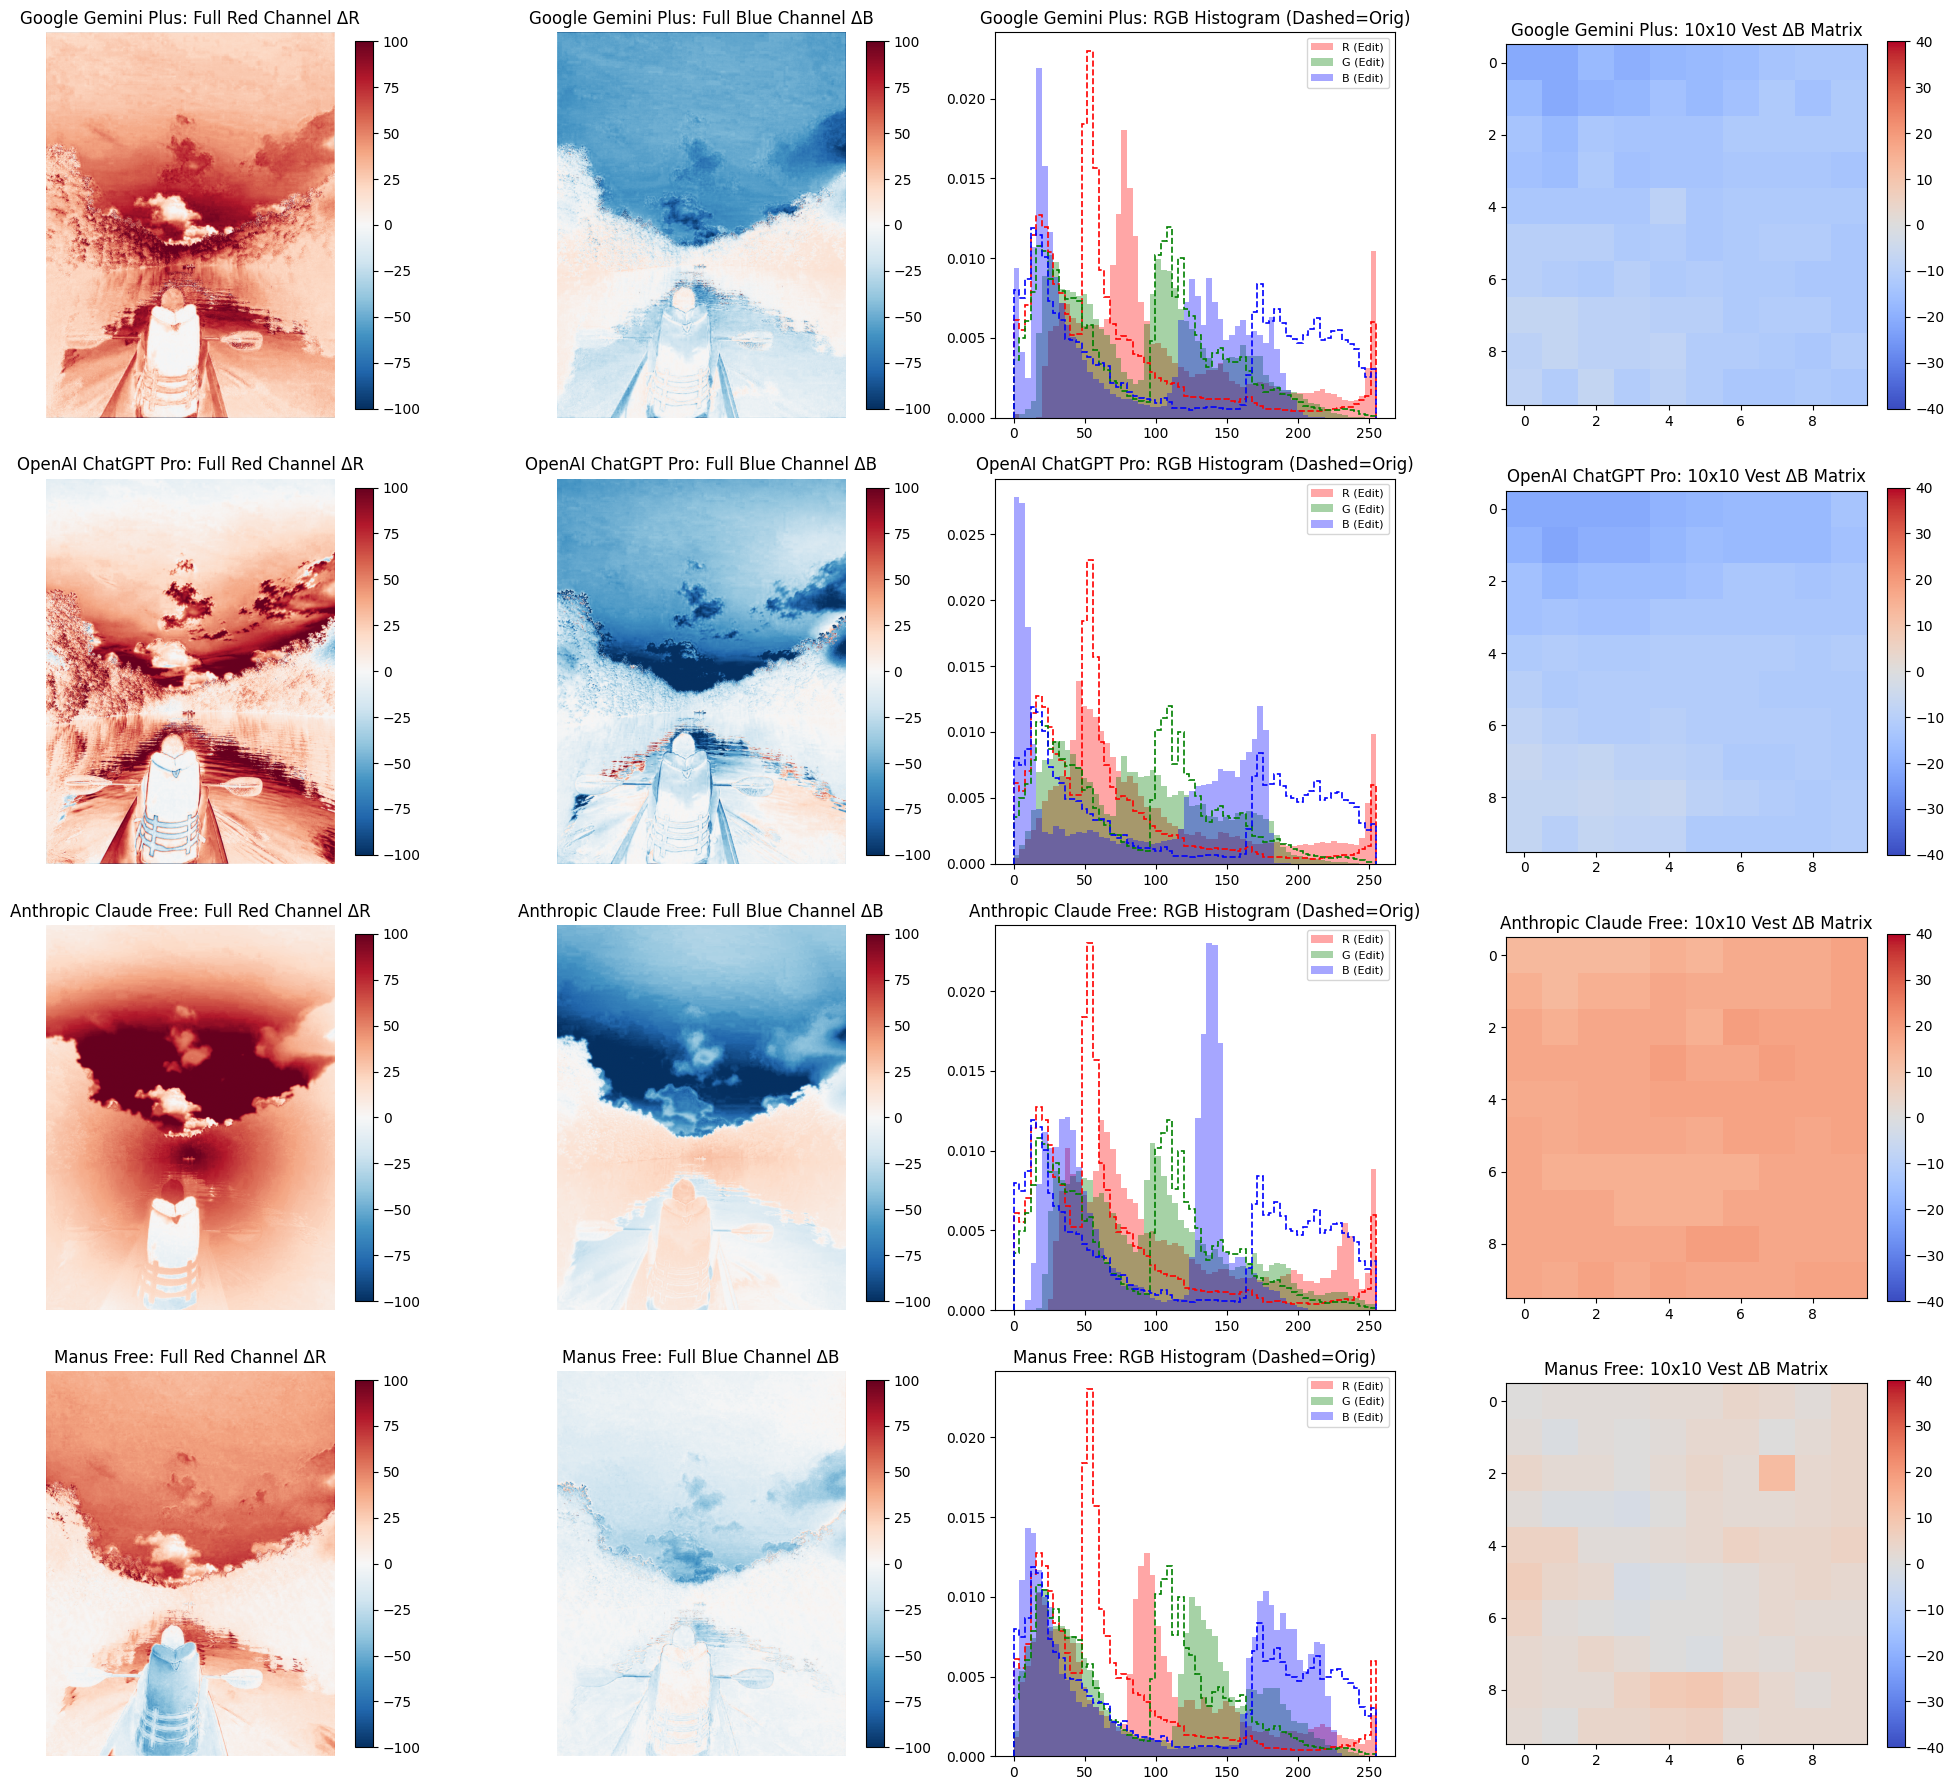


=== SUMMARY TABLE: GLOBAL & 10x10 CHANNEL SHIFTS ===


,Platform,Global Mean ΔR,Global Mean ΔG,Global Mean ΔB,10x10 Vest ΔR (Mean±Std),10x10 Vest ΔG (Mean±Std),10x10 Vest ΔB (Mean±Std)
0,Google Gemini Plus,38.97,7.52,-29.58,-0.88 ± 1.12,+15.45 ± 2.42,-12.62 ± 2.97
1,OpenAI ChatGPT Pro,31.15,2.01,-32.16,-2.98 ± 0.68,+3.90 ± 1.86,-12.67 ± 3.74
2,Anthropic Claude Free,46.22,14.02,-25.64,+0.01 ± 0.66,+29.97 ± 0.56,+16.64 ± 1.37
3,Manus Free,24.91,9.96,-9.58,-35.68 ± 2.19,+6.62 ± 1.76,+2.42 ± 2.25


In [ ]:
ctrl_rgb = cv2.cvtColor(cv2.imread(FILES["Original (Control)"]), cv2.COLOR_BGR2RGB)
h_ctrl, w_ctrl = ctrl_rgb.shape[:2]

def align_to_original(target_rgb, ref_rgb):
    sift = cv2.SIFT_create(nfeatures=4000)
    kp1, des1 = sift.detectAndCompute(cv2.cvtColor(ref_rgb, cv2.COLOR_RGB2GRAY), None)
    kp2, des2 = sift.detectAndCompute(cv2.cvtColor(target_rgb, cv2.COLOR_RGB2GRAY), None)
    bf = cv2.BFMatcher(cv2.NORM_L2)
    matches = [m for m, n in bf.knnMatch(des1, des2, k=2) if m.distance < 0.75 * n.distance]
    src_pts = np.float32([kp2[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp1[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
    H, _ = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    return cv2.warpPerspective(target_rgb, H, (ref_rgb.shape[1], ref_rgb.shape[0]), flags=cv2.INTER_LANCZOS4)

# Coordinates for a 10x10 patch on the orange life vest
px, py = int(w_ctrl * 0.42), int(h_ctrl * 0.78)
ctrl_patch = ctrl_rgb[py:py+10, px:px+10].astype(np.int16)

summary_rows = []
variants = [k for k in FILES.keys() if k != "Original (Control)"]

fig, axes = plt.subplots(len(variants), 4, figsize=(20, 4.5 * len(variants)))

for row, label in enumerate(variants):
    raw_rgb = cv2.cvtColor(cv2.imread(FILES[label]), cv2.COLOR_BGR2RGB)
    aligned = align_to_original(raw_rgb, ctrl_rgb)

    # Full-image signed channel differences (Generated - Original)
    diff_full = aligned.astype(np.int16) - ctrl_rgb.astype(np.int16)

    # 10x10 Life Vest patch differences
    patch = aligned[py:py+10, px:px+10].astype(np.int16)
    delta_patch = patch - ctrl_patch

    summary_rows.append({
        "Platform": label,
        "Global Mean ΔR": round(diff_full[:, :, 0].mean(), 2),
        "Global Mean ΔG": round(diff_full[:, :, 1].mean(), 2),
        "Global Mean ΔB": round(diff_full[:, :, 2].mean(), 2),
        "10x10 Vest ΔR (Mean±Std)": f"{delta_patch[:,:,0].mean():+.2f} ± {delta_patch[:,:,0].std():.2f}",
        "10x10 Vest ΔG (Mean±Std)": f"{delta_patch[:,:,1].mean():+.2f} ± {delta_patch[:,:,1].std():.2f}",
        "10x10 Vest ΔB (Mean±Std)": f"{delta_patch[:,:,2].mean():+.2f} ± {delta_patch[:,:,2].std():.2f}",
    })

    print(f"\n--- {label}: 10x10 Life Vest Patch ΔR (Red Channel Shift) ---")
    print(delta_patch[:, :, 0])

    # Col 1: Separate Red Channel Shift Heatmap across full image
    im_r = axes[row, 0].imshow(diff_full[:, :, 0], cmap="RdBu_r", vmin=-100, vmax=100)
    axes[row, 0].set_title(f"{label}: Full Red Channel ΔR")
    axes[row, 0].axis("off")
    plt.colorbar(im_r, ax=axes[row, 0], fraction=0.046)

    # Col 2: Separate Blue Channel Shift Heatmap across full image
    im_b = axes[row, 1].imshow(diff_full[:, :, 2], cmap="RdBu_r", vmin=-100, vmax=100)
    axes[row, 1].set_title(f"{label}: Full Blue Channel ΔB")
    axes[row, 1].axis("off")
    plt.colorbar(im_b, ax=axes[row, 1], fraction=0.046)

    # Col 3: RGB Channel Intensity Histograms (Original dashed vs Generated solid)
    for c_idx, (cname, col) in enumerate(zip(["R", "G", "B"], ["red", "green", "blue"])):
        axes[row, 2].hist(ctrl_rgb[:, :, c_idx].flatten(), bins=64, range=(0, 255),
                          color=col, histtype="step", linestyle="--", linewidth=1.2, density=True)
        axes[row, 2].hist(aligned[:, :, c_idx].flatten(), bins=64, range=(0, 255),
                          color=col, alpha=0.35, label=f"{cname} (Edit)", density=True)
    axes[row, 2].set_title(f"{label}: RGB Histogram (Dashed=Orig)")
    axes[row, 2].legend(loc="upper right", fontsize=8)

    # Col 4: 10x10 Life Vest Patch ΔB (Blue Channel Micro-Jitter)
    im_p = axes[row, 3].imshow(delta_patch[:, :, 2], cmap="coolwarm", vmin=-40, vmax=40)
    axes[row, 3].set_title(f"{label}: 10x10 Vest ΔB Matrix")
    plt.colorbar(im_p, ax=axes[row, 3], fraction=0.046)

plt.tight_layout()
plt.savefig("section2_hidden_channels_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

print("\n=== SUMMARY TABLE: GLOBAL & 10x10 CHANNEL SHIFTS ===")
display(pd.DataFrame(summary_rows))